In [43]:
import tiktoken
tokenizer = tiktoken.get_encoding("cl100k_base")

import numpy as np
import matplotlib.pyplot as plt

In [44]:
import requests
import re

text = requests.get('https://www.gutenberg.org/files/35/35-0.txt').text
len(text)

179799

In [45]:
# split by punctuation
words = re.split(r'([,.:;—?_!"“()\']|--|\s)',text)
words = [item.strip() for item in words if item.strip()]

tokenCount = np.zeros((len(words),2),dtype=int)
print(tokenCount.shape)

for idx,w in enumerate(words):
  tokenCount[idx,0] = len(w) # first column is the length of the word
  tokenCount[idx,1] = len(tokenizer.encode(w)) # second column is the number of token
  
  print(f'{tokenCount[idx,0]} chars in "{w}" -> {tokenCount[idx,1]} tokens')
  

(37789, 2)
3 chars in "***" -> 1 tokens
5 chars in "START" -> 1 tokens
2 chars in "OF" -> 1 tokens
3 chars in "THE" -> 1 tokens
7 chars in "PROJECT" -> 1 tokens
9 chars in "GUTENBERG" -> 5 tokens
5 chars in "EBOOK" -> 2 tokens
2 chars in "35" -> 1 tokens
3 chars in "***" -> 1 tokens
3 chars in "The" -> 1 tokens
4 chars in "Time" -> 1 tokens
7 chars in "Machine" -> 1 tokens
2 chars in "An" -> 1 tokens
9 chars in "Invention" -> 2 tokens
2 chars in "by" -> 1 tokens
1 chars in "H" -> 1 tokens
1 chars in "." -> 1 tokens
1 chars in "G" -> 1 tokens
1 chars in "." -> 1 tokens
5 chars in "Wells" -> 2 tokens
8 chars in "CONTENTS" -> 2 tokens
1 chars in "I" -> 1 tokens
12 chars in "Introduction" -> 1 tokens
2 chars in "II" -> 1 tokens
3 chars in "The" -> 1 tokens
7 chars in "Machine" -> 1 tokens
3 chars in "III" -> 1 tokens
3 chars in "The" -> 1 tokens
4 chars in "Time" -> 1 tokens
9 chars in "Traveller" -> 3 tokens
7 chars in "Returns" -> 1 tokens
2 chars in "IV" -> 1 tokens
4 chars in "Time" ->

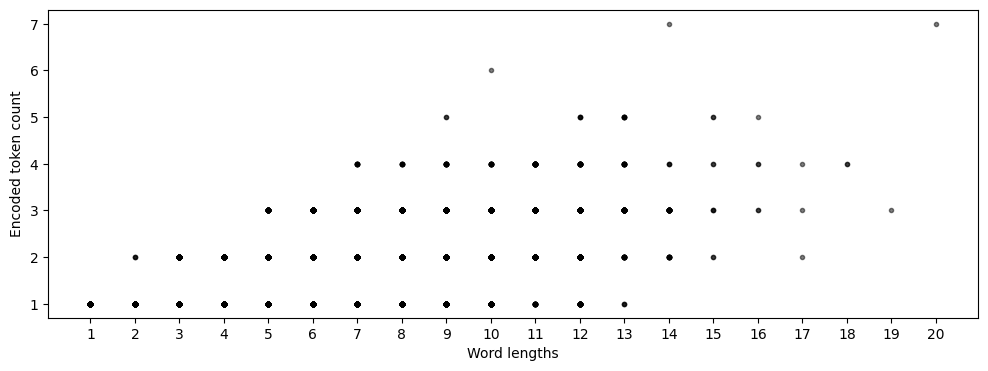

In [46]:
plt.figure(figsize=(12,4))

offsetsX = np.random.randn(len(words))/20
offsetsY = np.random.randn(len(words))/20

plt.plot(tokenCount[:,0],tokenCount[:,1],'k.',alpha=.5)
plt.gca().set(xlabel='Word lengths',ylabel='Encoded token count',xticks=np.arange(1,max(tokenCount[:,0])+1))

plt.show()

In [47]:
for idx,w in enumerate(words):
    if len(w) == 14:
        print(f'{tokenCount[idx,0]} chars in "{w}" -> {tokenCount[idx,1]} tokens')

14 chars in "intermittently" -> 3 tokens
14 chars in "mathematicians" -> 3 tokens
14 chars in "Time-Dimension" -> 3 tokens
14 chars in "Time-Dimension" -> 3 tokens
14 chars in "Time-Dimension" -> 3 tokens
14 chars in "investigations" -> 3 tokens
14 chars in "Psychologist’s" -> 3 tokens
14 chars in "potentialities" -> 2 tokens
14 chars in "incredibleness" -> 4 tokens
14 chars in "aforementioned" -> 3 tokens
14 chars in "wool-gathering" -> 4 tokens
14 chars in "interpretation" -> 2 tokens
14 chars in "Nebuchadnezzar" -> 7 tokens
14 chars in "Psychologist’s" -> 3 tokens
14 chars in "overwhelmingly" -> 3 tokens
14 chars in "disappointment" -> 2 tokens
14 chars in "interrogations" -> 3 tokens
14 chars in "conversational" -> 3 tokens
14 chars in "characteristic" -> 2 tokens
14 chars in "specialisation" -> 2 tokens
14 chars in "interpretation" -> 2 tokens
14 chars in "interpretation" -> 2 tokens
14 chars in "self-restraint" -> 3 tokens
14 chars in "expostulations" -> 3 tokens
14 chars in "ill

In [48]:
wordsWith14Chars = set(np.where(tokenCount[:,0] == 14)[0])

for idx in wordsWith14Chars:
    this_decode = [tokenizer.decode([t]) for t in tokenizer.encode(words[idx])]
    print(f'{words[idx]} comprises of {this_decode}')

interpretation comprises of ['interpret', 'ation']
aforementioned comprises of ['a', 'fore', 'mentioned']
constellations comprises of ['const', 'ell', 'ations']
specialisation comprises of ['special', 'isation']
Time-Dimension comprises of ['Time', '-D', 'imension']
Psychologist’s comprises of ['Psych', 'ologist', '’s']
conversational comprises of ['con', 'vers', 'ational']
north-eastward comprises of ['north', '-east', 'ward']
Undergrounders comprises of ['Under', 'ground', 'ers']
mathematicians comprises of ['math', 'ematic', 'ians']
interpretation comprises of ['interpret', 'ation']
discriminating comprises of ['disc', 'rim', 'inating']
mountaineering comprises of ['mount', 'aine', 'ering']
ill-controlled comprises of ['ill', '-controlled']
Psychologist’s comprises of ['Psych', 'ologist', '’s']
North-eastward comprises of ['North', '-east', 'ward']
interrogations comprises of ['inter', 'rog', 'ations']
self-deception comprises of ['self', '-de', 'ception']
differentiated comprises o

# Token efficiency

it can be calculated by calculating the number of character divided be the number of tokens


for w in words:
    print(f'{len(w)} chars in "{w}" -> {len(tokenizer.encode(w))} tokens {w}')
    # token efficiency calculation
    efficiency = len(tokenizer.encode(w)) / len(w) if len(w) > 0 else 0
    print(f'  Token efficiency: {efficiency:.2f}')
tokenCount.shape

In [49]:
import pandas as pd
df = pd.DataFrame(tokenCount, columns=['word_length', 'token_count'])
df.head() # i wanted to use pandas to under the content of the data and to see if there are any patterns in the data. I also wanted to use pandas to see if there are any correlations between the word length and the token count.

,word_length,token_count
0,3,1
1,5,1
2,2,1
3,3,1
4,7,1


In [50]:
# there for word efficiency is basically

efficiency = tokenCount[:,0] / tokenCount[:,1]
efficiency

array([3. , 5. , 2. , ..., 2.5, 2. , 3. ], shape=(37789,))

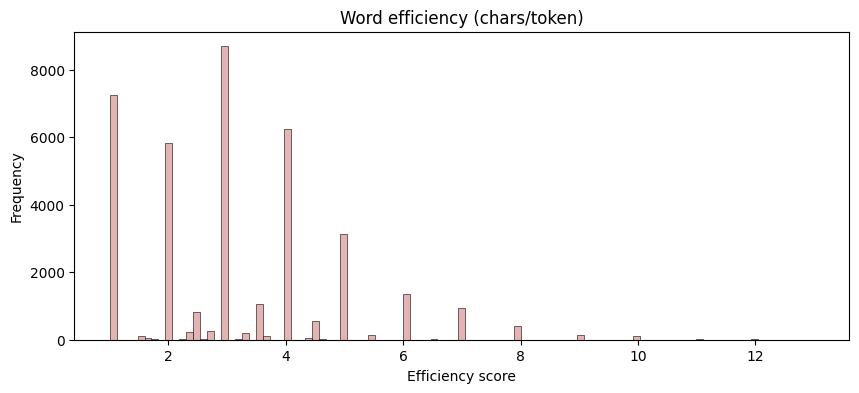

In [51]:
# show a historgram
plt.figure(figsize=(10,4))
plt.hist(efficiency,color=[.9,.7,.7],edgecolor='k',linewidth=.4,bins='fd')
plt.gca().set(xlabel='Efficiency score',ylabel='Frequency',title='Word efficiency (chars/token)')
plt.show()

In [52]:
# find the most and least efficiently tokenized words
max_efficiency = np.max(efficiency)
min_efficiency = np.min(efficiency)

# find all the words with those efficiency values
most_efficient_words = np.where(efficiency==max_efficiency)[0]
least_efficient_words = np.where(efficiency==min_efficiency)[0]

# find and print the unique words with max-efficiency score
most_efficient_words = list(set([ words[i] for i in most_efficient_words ]))

print('MOST EFFICIENT WORDS:')
for w in most_efficient_words:
  print(f'"{w}" has {max_efficiency} characters per token')

MOST EFFICIENT WORDS:
"advertisement" has 13.0 characters per token
"communication" has 13.0 characters per token


In [53]:
tmTokens = tokenizer.encode(text)

In [54]:
# repeat for min-efficiency score
print('\n\nLEAST EFFICIENT WORDS:')
for w in list(set([ words[i] for i in least_efficient_words ])):
  print(f'"{w}" has {min_efficiency:.2f} characters per token')



LEAST EFFICIENT WORDS:
"I" has 1.00 characters per token
"X" has 1.00 characters per token
"’" has 1.00 characters per token
"_" has 1.00 characters per token
"(" has 1.00 characters per token
"," has 1.00 characters per token
";" has 1.00 characters per token
"“" has 1.00 characters per token
"…" has 1.00 characters per token
"G" has 1.00 characters per token
"?" has 1.00 characters per token
"H" has 1.00 characters per token
"D" has 1.00 characters per token
":" has 1.00 characters per token
"—" has 1.00 characters per token
"A" has 1.00 characters per token
"‘I" has 1.00 characters per token
"." has 1.00 characters per token
"V" has 1.00 characters per token
"!" has 1.00 characters per token
")" has 1.00 characters per token
"]" has 1.00 characters per token
"a" has 1.00 characters per token
"XV" has 1.00 characters per token
"”" has 1.00 characters per token


In [55]:
# unique set of words as we've split them up
uniqueWords = set(words)
print(f'There are {len(uniqueWords)} unique words in The Time Machine according to our split.')

There are 5006 unique words in The Time Machine according to our split.


In [59]:
# random token
token_idx = np.random.randint(0,tokenizer.n_vocab//10)

# non-random tokens to try
# token_idx = 1879#,5030#,716

# find the words (from our split) in The Time Machine that contain that token
words_with_token = [w for w in uniqueWords if token_idx in tokenizer.encode(w)]

# find the context (from the full encoding) surrounding each token appearance
seqs_with_token = np.array(tmTokens)==token_idx

# print the token
print(f'Token {token_idx} is "{tokenizer.decode([token_idx])}"\n\n')

# its occurance in our manually split words
# its occurances in the GPT encoding
print(f'\n\n*** From encoding the full text: This token appears {sum(seqs_with_token)} times')
for s in np.where(seqs_with_token)[0]:
  print(f'{tokenizer.decode(tmTokens[s-5:s+6])}\n-----------')

Token 8893 is " patient"




*** From encoding the full text: This token appears 3 times
 me to be calm and patient, to learn
the
-----------
 be
calm and patient, find its hiding-place
-----------
 been glad to trace the patient
readjustments by
-----------
